# TD1 — Temporal data contract and forecasting baselines — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [3]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\maxim\Desktop\ESILV\ML_A5
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — lag-7 alignment

Complete the next-week forecast. The figure explains why forecast and target dates must align.

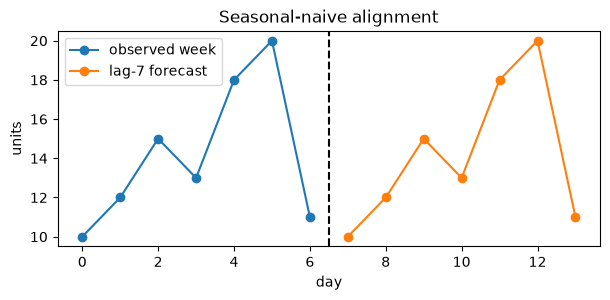

In [4]:
import numpy as np, matplotlib.pyplot as plt
toy_history=np.array([10,12,15,13,18,20,11],dtype=float)
toy_prediction=toy_history[-7:].copy()  # lag-7: day t+h reuses the observed value 7 days earlier
assert toy_prediction.shape==(7,) and np.array_equal(toy_prediction,toy_history[-7:])
fig,ax=plt.subplots(figsize=(7,2.8)); ax.plot(range(7),toy_history,marker='o',label='observed week')
if np.isfinite(toy_prediction).all(): ax.plot(range(7,14),toy_prediction,marker='o',label='lag-7 forecast')
ax.axvline(6.5,color='black',ls='--'); ax.set(xlabel='day',ylabel='units',title='Seasonal-naive alignment'); ax.legend(); plt.show()

## 1 — Decision and data contract

In [5]:
import hashlib, numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error
from shared.data import dataset_path
from shared.evaluation import smape
path=dataset_path('daily_demand_development.csv')
demand=pd.read_csv(path,parse_dates=['date'])
data_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
print(demand.shape,data_sha256[:16])
forecast_contract={'unit':'one calendar day','target':'demand_units','frequency':'daily','origin':demand.iloc[:-28].date.iloc[-1],'horizon_days':28,'known_at_origin':['date', 'promotion', 'holiday_period'],'protected_final_targets':True} # TODO
forecast_contract
# stockout_flag exclu : une rupture future dépend de la demande future,
# donc elle n'est pas connue de façon fiable à l'origine (risque de fuite).

(1433, 5) b275d65b07f44795


{'unit': 'one calendar day',
 'target': 'demand_units',
 'frequency': 'daily',
 'origin': Timestamp('2026-11-05 00:00:00'),
 'horizon_days': 28,
 'known_at_origin': ['date', 'promotion', 'holiday_period'],
 'protected_final_targets': True}

## 2 — Executable invariants and negative test

Implement every check; do not delete the supplied expected-failure test.

In [6]:
def assert_daily_contract(frame):
    assert isinstance(frame,pd.DataFrame) and {'date','demand_units'}<=set(frame)
    assert len(frame) == 1433, "nombre de lignes incorrect"
    assert frame.date.is_unique, "dates en double"
    assert frame.date.is_monotonic_increasing, "dates pas dans l'ordre"
    assert (frame.date.diff().dropna()==pd.Timedelta(days=1)).all, "jour manquant"
    assert np.isfinite(frame.date).all(), "cible non finie"
    assert frame.stockout_flag.isin([0,1]).all(), "stockout_flag non binaire"
    return None
assert_daily_contract(demand)
negative_test_passed=False
try: assert_daily_contract(demand.iloc[[0,0,1]])
except AssertionError: negative_test_passed=True
print('Expected negative test caught:',negative_test_passed)

Expected negative test caught: True


stockout_flag
0    86.20414
1    58.00000
Name: demand_units, dtype: float64

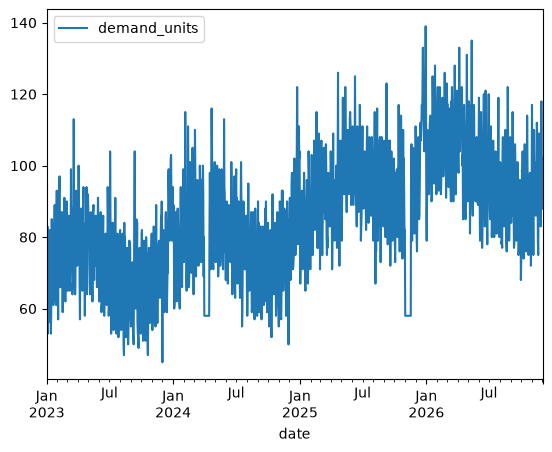

In [7]:
## 2b — Exploration
demand.plot(x='date', y='demand_units')
demand.groupby(demand.date.dt.dayofweek).demand_units.mean()
(demand.demand_units == 0).sum()
demand[['promotion','holiday_period','stockout_flag']].sum()
demand.groupby('promotion').demand_units.mean()
demand.groupby('stockout_flag').demand_units.mean()

In [8]:
demand[demand.stockout_flag == 1].demand_units.describe()


count    32.0
mean     58.0
std       0.0
min      58.0
25%      58.0
50%      58.0
75%      58.0
max      58.0
Name: demand_units, dtype: float64

In [9]:
demand.date.iloc[850]

Timestamp('2025-04-30 00:00:00')

In [10]:
demand.date.iloc[1200]

Timestamp('2026-04-15 00:00:00')

Une vraie demande varie toujours un peu d'un jour à l'autre. Une valeur parfaitement constante veut dire autre chose : le magasin n'avait que 58 unités et il a tout vendu. Les ventes ont été plafonnées par le stock. La vraie demande ces jours-là était au moins 58, peut-être 80 ou 100, mais on ne la connaîtra jamais.

C'est ça, la censure. Les deux segments plats du graphique sont exactement ces jours-là.

Pour la prévision, la conséquence est importante : ces jours-là, la colonne demand_units sous-estime la vraie demande. Un modèle entraîné dessus apprend « 58 » alors que les clients en voulaient plus.

## 3 — Freeze one public development block

In [11]:
train=demand.iloc[:-28].copy(); validation=demand.iloc[-28:].copy()
assert len(validation)==28 and train.date.max()<validation.date.min()
print(train.date.max(),validation.date.min())

2026-11-05 00:00:00 2026-11-06 00:00:00


## 4 — Three target-safe baselines

Fill only the three expressions; every value must come from training history.

In [12]:
def baseline_forecasts(train_values,horizon=28,season=7):
    train_values=np.asarray(train_values,float); assert len(train_values)>=season
    mean_forecast= np.full(horizon,train_values.mean())           # TODO
    last_value_forecast= np.full(horizon,train_values[-1])      # TODO
    seasonal_naive_forecast= np.tile(train_values[-7:],4) # TODO
    values=[mean_forecast,last_value_forecast,seasonal_naive_forecast]
    if any(v is None for v in values): return None
    result=dict(zip(['historical_mean','last_value','seasonal_naive'],map(np.asarray,values)))
    assert all(v.shape==(horizon,) and np.isfinite(v).all() for v in result.values()); return result
forecasts= baseline_forecasts(train.demand_units) # TODO: call when complete
print('Baselines pending' if forecasts is None else forecasts.keys())

dict_keys(['historical_mean', 'last_value', 'seasonal_naive'])


## 5 — Common metrics and explanatory figure

C:\Users\maxim\AppData\Local\Temp\ipykernel_48896\3283147280.py:6: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  for name,pred in forecasts.items(): ax.plot(validation.date,pred,label=name,alpha=.8)


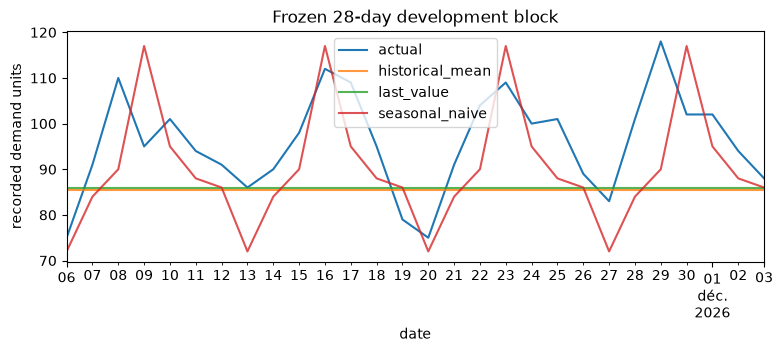

,model,mae,smape
0,historical_mean,12.557067,13.477491
1,last_value,12.107143,12.956200
2,seasonal_naive,9.607143,10.130650


In [13]:
scores=pd.DataFrame()
if forecasts is not None:
    actual=validation.demand_units.to_numpy(float)
    scores=pd.DataFrame([{'model':name,'mae':mean_absolute_error(actual,pred),'smape':smape(actual,pred)} for name,pred in forecasts.items()])
    ax=validation.plot(x='date',y='demand_units',figsize=(9,3),label='actual')
    for name,pred in forecasts.items(): ax.plot(validation.date,pred,label=name,alpha=.8)
    ax.set(title='Frozen 28-day development block',ylabel='recorded demand units'); ax.legend(); plt.show()
scores

In [14]:
check = validation[['date','demand_units','promotion']].copy()
check['seasonal_naive'] = forecasts['seasonal_naive']
check['erreur'] = (check.demand_units - check.seasonal_naive).abs()
check.sort_values('erreur', ascending=False).head(5)


,date,demand_units,promotion,seasonal_naive,erreur
1428,2026-11-29,118,1,90.0,28.0
1408,2026-11-09,95,0,117.0,22.0
1407,2026-11-08,110,1,90.0,20.0
1427,2026-11-28,101,1,84.0,17.0
1429,2026-11-30,102,0,117.0,15.0


## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [17]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation='''Le seasonal-naive gagne et se trompe en moyenne de 9,6 unités par jour, contre environ 12 pour les deux autres, soit environ 20 pourcent d'erreur en moins. Ce qui est normal puisque c'est la seule baseline qui capte le motif hebdomadaire (en rouge). Mais c'est un seul bloc de 28 jours donc on ne peut pas en conclure que le seasonal-naive est meilleur en général.\n La moyenne historique n'est pas au bon niveau. Sur le graphique, la ligne orange est à environ 85, alors que la courbe bleue est presque toujours au-dessus, autour de 96 en moyenne.\n La moyenne sous-estime systématiquement la demande.  3 des 5 pires erreurs (29/11, 08/11, 28/11) tombent sur des jours de promotion. À chaque fois, le seasonal-naive sous-estime, avec par exemple 118 vendus pour 90 prévus. Il recopie la semaine passée, qui n'avait pas de promo à ces dates.'''
print(interpretation or 'Interpretation pending.')

Le seasonal-naive gagne et se trompe en moyenne de 9,6 unités par jour, contre environ 12 pour les deux autres, soit environ 20 pourcent d'erreur en moins. Ce qui est normal puisque c'est la seule baseline qui capte le motif hebdomadaire (en rouge). Mais c'est un seul bloc de 28 jours donc on ne peut pas en conclure que le seasonal-naive est meilleur en général.
 La moyenne historique n'est pas au bon niveau. Sur le graphique, la ligne orange est à environ 85, alors que la courbe bleue est presque toujours au-dessus, autour de 96 en moyenne.
 La moyenne sous-estime systématiquement la demande.  3 des 5 pires erreurs (29/11, 08/11, 28/11) tombent sur des jours de promotion. À chaque fois, le seasonal-naive sous-estime, avec par exemple 118 vendus pour 90 prévus. Il recopie la semaine passée, qui n'avait pas de promo à ces dates.


## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.